# 10 — Paper plots

Figures for the paper, written to
`/Users/user/Documents/Codes/Papers_and_reports/moonrunes_paper/figures/` as PDF (vector) and
PNG. Their captions are in `figures/README.md`.

| file | figure |
|---|---|
| `tris_maps` | the TRIS maps made with limTOD (600 and 820 MHz), and the 2.5 GHz points |
| `beam_matching_stockert` | Stockert + Villa-Elisa 1420 MHz before and after matching to the TRIS beam |
| `sed_fit_tod_route` | the SED fit along the TRIS ring (TOD route) |
| `sed_fit_map_route` | the SED fit per pixel of the TRIS stripe (map route) |
| `tods_all_maps` | every map observed through the TRIS beam with limTOD |

**Style.** Every figure is drawn at its printed size: the MNRAS full text width (174 mm),
9–10 pt text, so it reads on an A4 page as it appears here. Sky maps carry no gridlines.
They use one perceptually uniform colour map (viridis) on a logarithmic stretch, which
spreads the faint sky and the bright plane across the whole scale. Grey means no data.
Each survey keeps one colour across every line plot.

All numbers come from the pipeline itself: the stage 1 products, `match_to_tris_beam` (the
stage 2 / map-route beam matching, with the configured kernel) and
`moonrunes.sed_prototype` (both SED routes).

In [1]:
%matplotlib inline
import os
os.environ["TQDM_DISABLE"] = "1"
import sys
import warnings
from pathlib import Path

import numpy as np
import healpy as hp
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO / "src"))
warnings.filterwarnings("ignore")

from moonrunes.config import load_config
from moonrunes import frames, sky_maps, sed_prototype as sp
from moonrunes.stage1_tris_maps import load_stage1, import_limtod_tris
from moonrunes.stage2_beam_matching import match_to_tris_beam

OUT = Path("/Users/user/Documents/Codes/Papers_and_reports/moonrunes_paper/figures")
OUT.mkdir(parents=True, exist_ok=True)

# Print-size typography: figures are made at their final width, so these sizes are the
# sizes on the page.
FULL_WIDTH = 174 / 25.4          # MNRAS full text width, inches
plt.rcParams.update({
    "font.size": 9, "axes.titlesize": 9.5, "axes.labelsize": 9.5,
    "xtick.labelsize": 8.5, "ytick.labelsize": 8.5, "legend.fontsize": 8.5,
    "figure.dpi": 150, "savefig.dpi": 300, "pdf.fonttype": 42, "ps.fonttype": 42,
    "axes.grid": False, "figure.facecolor": "white", "savefig.facecolor": "white",
})
CMAP = plt.get_cmap("viridis").copy()
CMAP.set_bad("#d9d9d9")

def save(fig, name):
    for ext in ("pdf", "png"):
        fig.savefig(OUT / f"{name}.{ext}", bbox_inches="tight")
    print(f"saved {OUT / name}.pdf / .pdf")

config = load_config(REPO / "configs" / "run_config.yaml")
tris = import_limtod_tris(config)
stage1 = load_stage1(config)
BAND = stage1["band_mask"].astype(bool)
NSIDE = stage1.nside

# One colour per survey, used in every line plot.
COLOUR = {
    "LWA1 35 MHz": "#1f77b4", "Maipu + MU 45 MHz": "#17becf", "LWA1 80 MHz": "#2ca02c",
    "TRIS 600 MHz": "#d62728", "TRIS 820 MHz": "#ff7f0e",
    "CHIPASS 1400 MHz": "#9467bd", "Stockert + Villa-Elisa 1420 MHz": "#8c564b",
    "Rhodes/HartRAO 2326 MHz": "#e377c2", "ARCADE 2 3.15 GHz": "#bcbd22",
    "ARCADE 2 3.41 GHz": "#4d4d4d",
}

def survey_key(name):
    # Map the names the SED code uses for TRIS onto the colour keys.
    for f in ("600", "820"):
        if name.startswith(f"TRIS {f}"):
            return f"TRIS {f} MHz"
    return name

# Sky-map projections drawn directly with matplotlib (no healpy text, no graticule).
def mollweide_image(m, xsize=1400):
    # Returns (projector, image, missing): `image` is NaN both outside the ellipse and on
    # unobserved pixels; `missing` is True only on unobserved pixels INSIDE the ellipse,
    # so those can be drawn grey while the area outside the map stays blank.
    proj = hp.projector.MollweideProj(xsize=xsize)
    nside = hp.get_nside(m)
    raw = proj.projmap(m, lambda x, y, z: hp.vec2pix(nside, x, y, z))
    inside = proj.projmap(np.ones(m.size), lambda x, y, z: hp.vec2pix(nside, x, y, z)) == 1
    img = np.where(inside & np.isfinite(raw) & (raw > hp.UNSEEN / 2), raw, np.nan)
    missing = inside & ~np.isfinite(img)
    return proj, img, missing

def radec_image(m, ra=np.linspace(360, 0, 1441), dec=np.linspace(0, 85, 341)):
    # Nearest-pixel sampling on an RA/Dec grid (RA increasing to the left), so pixels
    # appear as they are, not interpolated.
    R, D = np.meshgrid(ra, dec)
    vals = m[hp.ang2pix(hp.get_nside(m), R, D, lonlat=True)]
    return np.where(np.isfinite(vals), vals, np.nan), [ra[0], ra[-1], dec[0], dec[-1]]

print(f"stage 1: {stage1.maps_path.name}, nside {NSIDE}; beam_matching.kernel = {config.require('beam_matching.kernel')}")
print(f"figures go to {OUT}")

stage 1: tris_maps_tris_haslam_v0.npz, nside 16; beam_matching.kernel = circular_gaussian
figures go to /Users/user/Documents/Codes/Papers_and_reports/moonrunes_paper/figures


---
## Figure 1 — The TRIS maps made with limTOD

Stage 1's maps at 600 and 820 MHz, made from the absolutely calibrated drift rings with
limTOD's Wiener-filter map-maker (`outputs/stage1/`): sky temperature (the fitted zero
level is not added), equatorial, on the nside 16 grid, shown only over the stripe the
TRIS beam observed. The 2.5 GHz channel is not a ring but 6 sky-temperature samples, so no
map is made from it; the bottom panel shows those samples on the same RA axis.

saved /Users/user/Documents/Codes/Papers_and_reports/moonrunes_paper/figures/tris_maps.pdf / .pdf


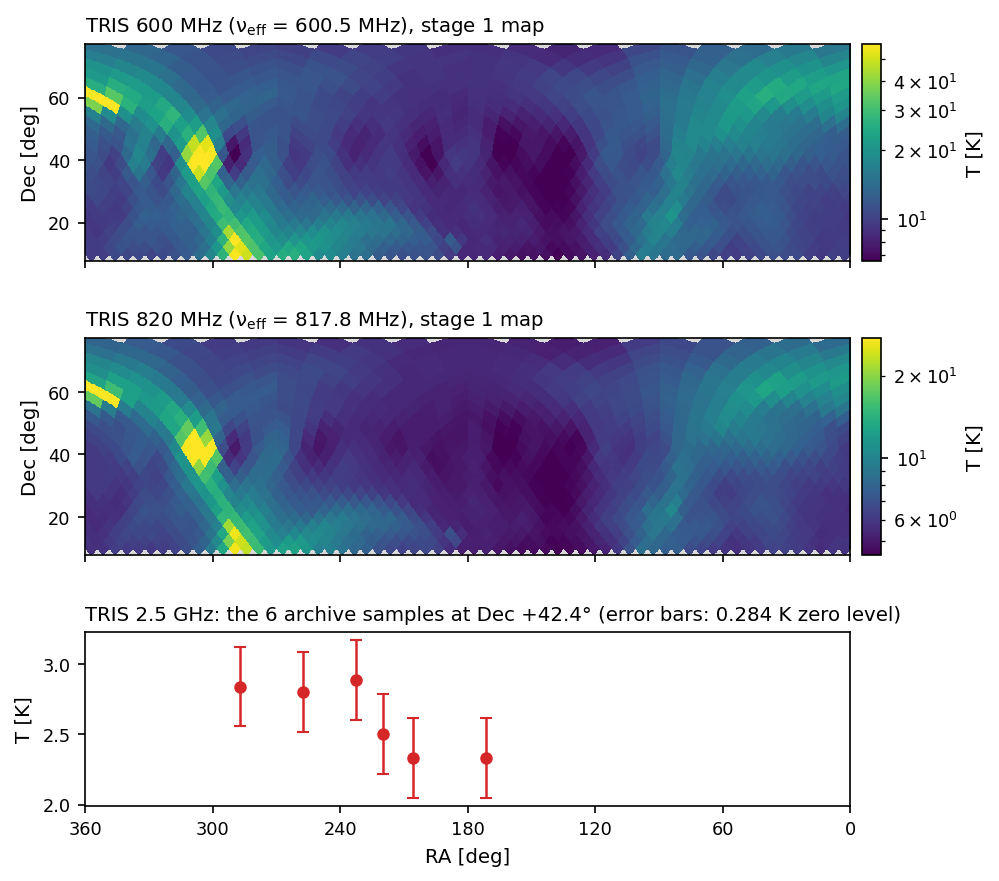

stripe Dec +7.8° to +77.2°; 2.5 GHz samples: RA 172° 2.329 K, RA 206° 2.331 K, RA 220° 2.503 K, RA 233° 2.886 K, RA 257° 2.800 K, RA 287° 2.840 K
600 MHz map: 6.17–133.50 K over 1272 pixels; fitted zero level +1.74 K (not added)
820 MHz map: 4.22–51.28 K over 1272 pixels; fitted zero level +0.52 K (not added)


In [2]:
ring_file = config.resolve_path("paths.tris_archive_dir")
points = tris.read_tris_point_set(ring_file / "TRIS_absolute_2500MHz.txt")
zero = points.zero_level_uncertainty_k
zero = float(zero) if np.isscalar(zero) else max(zero.positive_k, zero.negative_k)
# The archive publishes no per-sample statistical error at 2.5 GHz (None), only the zero level.
stat = (np.zeros(len(points.ra_deg)) if points.statistical_uncertainty_k is None
        else np.asarray(points.statistical_uncertainty_k, dtype=float))

band_dec = hp.pix2ang(NSIDE, np.flatnonzero(BAND), lonlat=True)[1]
half = hp.nside2resol(NSIDE, arcmin=True) / 60 / 2
dec_lo, dec_hi = band_dec.min() - half, band_dec.max() + half

fig = plt.figure(figsize=(FULL_WIDTH, 6.6))
gs = fig.add_gridspec(3, 2, width_ratios=[1, 0.025], height_ratios=[1, 1, 0.8], hspace=0.38, wspace=0.03)
for row, f in enumerate((600, 820)):
    i = stage1.index(f)
    m = stage1.band_map("sky_k", f)
    img, ext = radec_image(m, dec=np.linspace(dec_lo, dec_hi, 281))
    ax = fig.add_subplot(gs[row, 0])
    lo, hi = np.nanpercentile(img, [1, 99.5])
    im = ax.imshow(img, origin="lower", extent=ext, aspect="auto", cmap=CMAP, norm=LogNorm(lo, hi),
                   interpolation="nearest")
    nu = float(stage1["effective_freq_mhz"][i])
    ax.set_title(f"TRIS {f} MHz (ν$_\\mathrm{{eff}}$ = {nu:.1f} MHz), stage 1 map", loc="left")
    ax.set_ylabel("Dec [deg]")
    ax.set_xticks(np.arange(360, -1, -60)); ax.tick_params(labelbottom=False)
    cax = fig.add_subplot(gs[row, 1])
    cb = fig.colorbar(im, cax=cax)
    cb.set_label("T [K]")
ax = fig.add_subplot(gs[2, 0])
yerr = np.hypot(stat, zero)
ax.errorbar(points.ra_deg, points.temperature_k, yerr=yerr, fmt="o", ms=5, color="#d62728",
            ecolor="#d62728", elinewidth=1.2, capsize=3)
ax.set_xlim(360, 0); ax.set_xticks(np.arange(360, -1, -60))
ax.set_xlabel("RA [deg]"); ax.set_ylabel("T [K]")
ax.set_title(f"TRIS 2.5 GHz: the 6 archive samples at Dec +42.4° (error bars: {zero:.3f} K zero level)",
             loc="left")
save(fig, "tris_maps")
plt.show()
print(f"stripe Dec {dec_lo:+.1f}° to {dec_hi:+.1f}°; 2.5 GHz samples: "
      + ", ".join(f"RA {r:.0f}° {t:.3f} K" for r, t in zip(points.ra_deg, points.temperature_k)))
for f in (600, 820):
    m = stage1.band_map("sky_k", f)
    print(f"{f} MHz map: {np.nanmin(m):.2f}–{np.nanmax(m):.2f} K over {BAND.sum()} pixels; fitted zero level "
          f"{float(stage1['zero_level_k'][stage1.index(f)]):+.2f} K (not added)")

---
## Figure 2 — Beam matching: Stockert + Villa-Elisa 1420 MHz

Before: the survey at its native resolution (35.4′ beam, nside 256), rotated into
equatorial. After: the same map through the pipeline's beam matching
(`match_to_tris_beam`) with the **circular Gaussian kernel** (`circular_gaussian`), the one
that made the current stage 2 product: `hp.smoothing` to 23.366° FWHM (the larger TRIS
axis), quadrature kernel, mask-aware, then onto the nside 16 grid. The kernel is set
explicitly here, whatever `beam_matching.kernel` says in the config. Same logarithmic
colour scale in both. The dashed lines mark the TRIS stripe's declination limits.

Stockert + Villa-Elisa 1420 MHz: native nside 256, beam 0.590°; kernel circular_gaussian, target 23.366°, extra kernel 23.359°; 3069 of 3072 nside 16 pixels kept
saved /Users/user/Documents/Codes/Papers_and_reports/moonrunes_paper/figures/beam_matching_stockert.pdf / .pdf


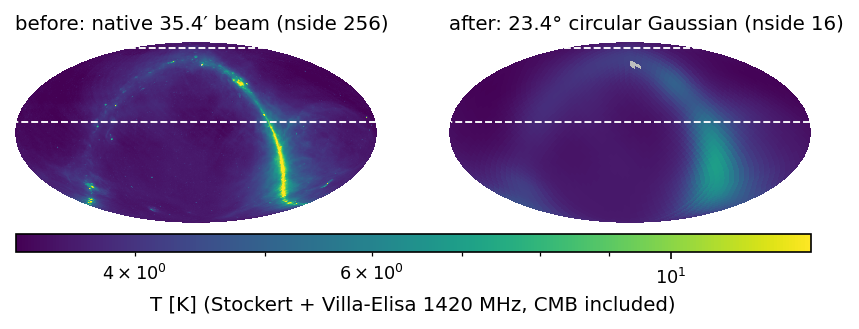

In [3]:
from matplotlib.colors import ListedColormap
ALL = sky_maps.discover(REPO / "res")
STOCKERT = next(m for m in ALL if m["file"].startswith("STOCKERT"))
sky = STOCKERT["sky"]
obs = np.isfinite(sky)
rot, obs_rot, _ = frames.rotate_masked(sky, obs, (STOCKERT["frame"], "C"))
before = np.where(obs_rot, rot, np.nan)
# The circular Gaussian kernel, as used for the current stage 2 product (set explicitly,
# independent of beam_matching.kernel in the config).
config_circ = load_config(config.path)
config_circ._data["beam_matching"]["kernel"] = "circular_gaussian"
after_vals, kept, info = match_to_tris_beam(rot, obs_rot, STOCKERT["fwhm_deg"], config_circ, nside_out=NSIDE)
after = np.where(kept, after_vals, np.nan)
print(f"{STOCKERT['name']}: native nside {STOCKERT['nside']}, beam {STOCKERT['fwhm_deg']:.3f}°; kernel "
      f"{info['kernel']}, target {info['target_fwhm_deg']}°, extra kernel {info['extra_fwhm_deg']:.3f}°; "
      f"{int(kept.sum())} of {kept.size} nside {NSIDE} pixels kept")

lo, hi = np.nanpercentile(before, [1, 99.7])
fig, axes = plt.subplots(1, 2, figsize=(FULL_WIDTH, 2.55))
for ax, m, title in zip(axes, (before, after),
                        ("before: native 35.4′ beam (nside 256)", "after: 23.4° circular Gaussian (nside 16)")):
    proj, img, missing = mollweide_image(m)
    cmap_clear = CMAP.copy(); cmap_clear.set_bad((0, 0, 0, 0))     # outside the ellipse: blank
    im = ax.imshow(img, origin="lower", extent=proj.get_extent(), cmap=cmap_clear, norm=LogNorm(lo, hi),
                   interpolation="nearest")
    if missing.any():                                              # unobserved sky: grey
        ax.imshow(np.where(missing, 1.0, np.nan), origin="lower", extent=proj.get_extent(),
                  cmap=ListedColormap(["#bdbdbd"]), vmin=0, vmax=2, interpolation="nearest")
    for d in (dec_lo, dec_hi):
        ra_l = np.linspace(-179.9, 179.9, 400)
        x, y = proj.ang2xy(ra_l, np.full_like(ra_l, d), lonlat=True)
        ax.plot(x, y, "--", color="white", lw=0.9)
    ax.set_title(title, loc="left")
    ax.axis("off")
cb = fig.colorbar(im, ax=axes, orientation="horizontal", fraction=0.06, pad=0.04, aspect=45)
cb.set_label("T [K] (Stockert + Villa-Elisa 1420 MHz, CMB included)")
save(fig, "beam_matching_stockert")
plt.show()

---
## The SED fits (Figures 3 and 4)

`moonrunes.sed_prototype` with the destriped-only Haslam map as the target, exactly as in
`notebooks/07` and `08`: every usable map in `res/`, TRIS included. Building the inputs
observes every map through the TRIS beam with limTOD and matches every map to the TRIS beam
on the nside 16 grid, so this cell takes several minutes.

In [4]:
inp = sp.Inputs(config, REPO / "res", target_file="HASLAM_DESTRIPED_ONLY.fits")
MR = sp.map_route(inp)
TR = sp.tod_route(inp)
CMB408 = sky_maps.cmb_rj_k(sp.NU0_MHZ)
NU_GRID = np.geomspace(25, 4500, 200)

def sed_panel(ax, axr, nu, t, s, names, r, haslam_excess, title):
    for n_, t_, s_, name in zip(nu, t, s, names):
        c = COLOUR[survey_key(name)]
        ax.errorbar(n_, t_, yerr=s_, fmt="o", ms=4.5, color=c, elinewidth=1.1, capsize=2)
        axr.errorbar(n_, (t_ - sp.power_law(n_, r["A"], r["beta"])) / s_, yerr=1, fmt="o", ms=3.5,
                     color=c, elinewidth=0.9)
    ax.plot(NU_GRID, sp.power_law(NU_GRID, r["A"], r["beta"]), "-", color="#555555", lw=1.2)
    ax.plot(408, haslam_excess, "x", mfc="none", mec="magenta", ms=7, mew=1.3)
    for a in (ax, axr):
        a.set_xscale("log"); a.set_xlim(25, 4500)
    ax.set_yscale("log")
    ax.set_title(title, loc="left", fontsize=8.5, linespacing=1.15)
    ax.tick_params(labelbottom=False)
    axr.axhline(0, color="#555555", lw=0.8)

def legend_for(fig, used):
    order = sorted(used, key=lambda n: list(COLOUR).index(n))
    handles = [plt.Line2D([], [], marker="o", ls="", ms=5, color=COLOUR[n], label=n) for n in order]
    handles.append(plt.Line2D([], [], marker="x", ls="", ms=6, mfc="none", mec="magenta", label="Haslam 408 MHz (not fitted)"))
    handles.append(plt.Line2D([], [], color="#555555", lw=1.2, label="fitted power law"))
    fig.legend(handles=handles, loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 0.075))
print(f"map route: {int(np.isfinite(MR['beta'][BAND]).sum())} stripe pixels fitted, median β {np.nanmedian(MR['beta'][BAND]):+.3f}")
print(f"TOD route: {int(np.isfinite(TR['beta']).sum())} ring samples fitted, median β {np.nanmedian(TR['beta']):+.3f}, "
      f"median prediction − Haslam {np.nanmedian(TR['delta_tod']):+.2f} K "
      f"({100 * np.nanmedian(TR['delta_tod'] / TR['target_tod']):+.1f}%)")

building the TRIS-grid (beam-matched) and raw nside 16 maps...
simulating TRIS TODs of every map with limTOD...
map route: 1272 stripe pixels fitted, median β -2.528
TOD route: 120 ring samples fitted, median β -2.485, median prediction − Haslam +3.22 K (+10.9%)


---
## Figure 3 — SED fit along the TRIS ring (TOD route)

Six of the 120 ring samples, spread in RA (ARCADE 2 is excluded, `sed.exclude_maps`). Each
panel shows the CMB-free brightness temperature of every survey, observed through the TRIS
beam with limTOD, and the real TRIS ring data. The fitted power law is drawn through them,
and Haslam's own TOD value is shown at 408 MHz (open square, not fitted). The small panel
below each is the residual in units of the error bar.

saved /Users/user/Documents/Codes/Papers_and_reports/moonrunes_paper/figures/sed_fit_tod_route.pdf / .pdf


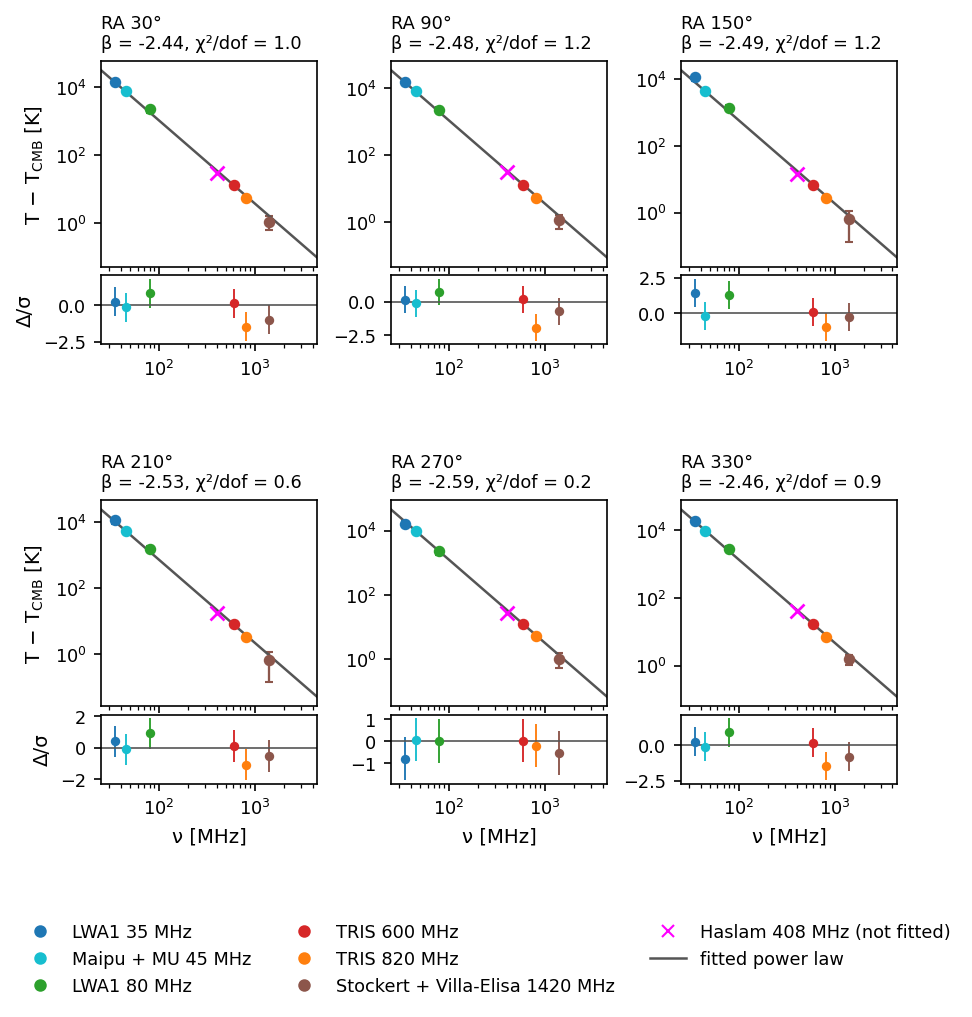

RA  30.0°: 6 points, β -2.440 ± 0.007, χ²/dof 0.98, prediction − Haslam +3.64 K
RA  90.0°: 6 points, β -2.484 ± 0.007, χ²/dof 1.23, prediction − Haslam +1.97 K
RA 150.0°: 6 points, β -2.486 ± 0.008, χ²/dof 1.23, prediction − Haslam +3.14 K
RA 210.0°: 6 points, β -2.529 ± 0.008, χ²/dof 0.62, prediction − Haslam +3.77 K
RA 270.0°: 6 points, β -2.591 ± 0.007, χ²/dof 0.24, prediction − Haslam +5.00 K
RA 330.0°: 6 points, β -2.458 ± 0.007, χ²/dof 0.93, prediction − Haslam +1.04 K


In [5]:
tpts = TR["points"]
samples = sorted(tpts, key=lambda k: inp.ra[k])
with_arc = [k for k in samples if any("ARCADE" in n for n in tpts[k][3])]
without = [k for k in samples if k not in with_arc]
# Samples spread round the ring (four, plus two on ARCADE 2 if it is in the fit).
targets = (30.0, 100.0, 170.0, 210.0) if with_arc else (30.0, 90.0, 150.0, 210.0, 270.0, 330.0)
pick = [min(without, key=lambda k: abs(inp.ra[k] - t)) for t in targets]
pick += [with_arc[i] for i in (len(with_arc) // 4, 3 * len(with_arc) // 4)] if with_arc else []
pick = sorted(dict.fromkeys(pick), key=lambda k: inp.ra[k])[:6]

fig = plt.figure(figsize=(FULL_WIDTH, 6.6))
outer = fig.add_gridspec(2, 3, hspace=0.55, wspace=0.34, bottom=0.2, top=0.93)
used = set()
for k, t_idx in enumerate(pick):
    nu, t, s, names, r = tpts[t_idx]
    inner = outer[k // 3, k % 3].subgridspec(2, 1, height_ratios=[3, 1], hspace=0.06)
    ax, axr = fig.add_subplot(inner[0]), fig.add_subplot(inner[1])
    sed_panel(ax, axr, nu, t, s, names, r, TR["target_tod"][t_idx] - CMB408,
              f"RA {inp.ra[t_idx]:.0f}°\nβ = {r['beta']:.2f}, χ²/dof = {r['chi2_dof']:.1f}")
    used |= {survey_key(n) for n in names}
    if k % 3 == 0:
        ax.set_ylabel("T − T$_\\mathrm{CMB}$ [K]"); axr.set_ylabel("Δ/σ")
    if k // 3 == 1:
        axr.set_xlabel("ν [MHz]")
legend_for(fig, used)
save(fig, "sed_fit_tod_route")
plt.show()
for t_idx in pick:
    nu, t, s, names, r = tpts[t_idx]
    print(f"RA {inp.ra[t_idx]:5.1f}°: {len(nu)} points, β {r['beta']:+.3f} ± {r['sigma_beta']:.3f}, χ²/dof {r['chi2_dof']:.2f}, "
          f"prediction − Haslam {TR['delta_tod'][t_idx]:+.2f} K")

---
## Figure 4 — SED fit per pixel (map route)

Six TRIS-stripe pixels across the range of sky brightness (ARCADE 2 is excluded,
`sed.exclude_maps`). Each panel shows every survey matched to the TRIS beam on the nside 16 grid, with
TRIS from the stage 1 maps plus the fitted zero level. The fitted power law is drawn
through them, and the beam-matched Haslam pixel is shown at 408 MHz (open square, not
fitted). The small panel below each is the residual in units of the error bar.

saved /Users/user/Documents/Codes/Papers_and_reports/moonrunes_paper/figures/sed_fit_map_route.pdf / .pdf


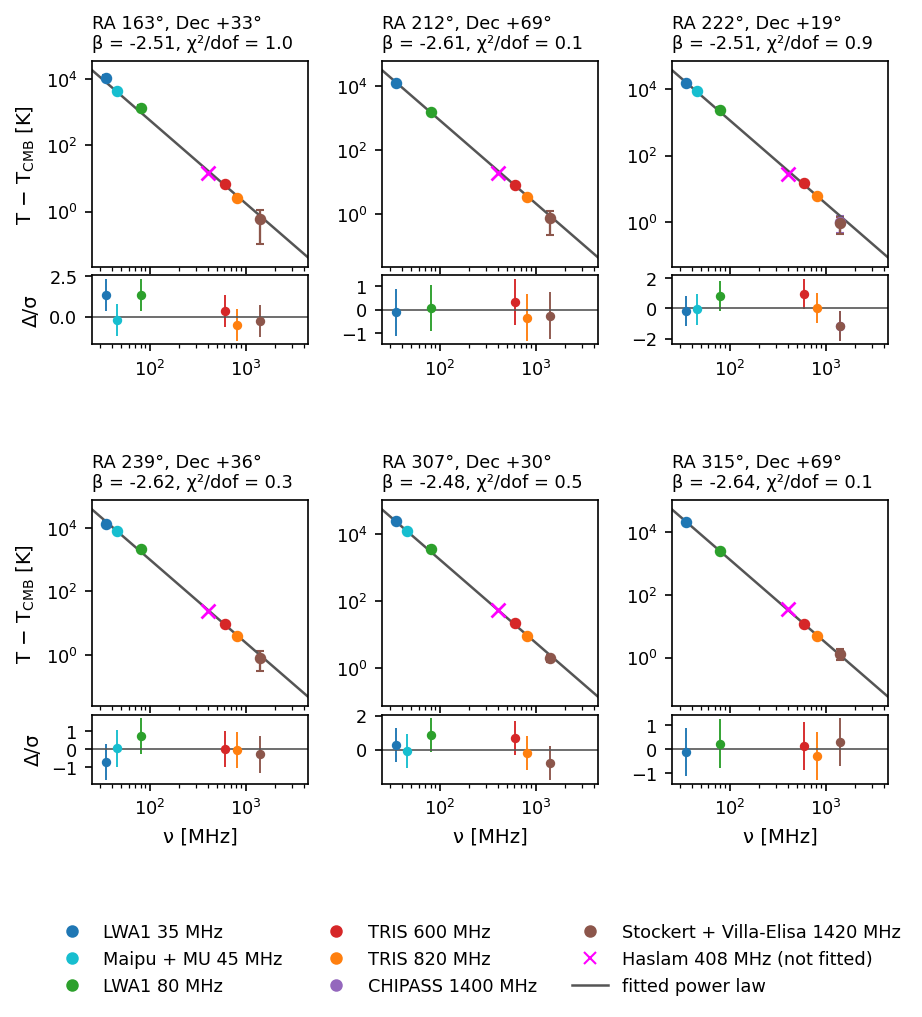

RA 163.1° Dec +32.8°: 6 points, β -2.513 ± 0.041, χ²/dof 1.04, prediction − Haslam +2.41 K
RA 212.1° Dec +69.4°: 5 points, β -2.614 ± 0.065, χ²/dof 0.10, prediction − Haslam +2.79 K
RA 222.2° Dec +19.5°: 7 points, β -2.507 ± 0.031, χ²/dof 0.86, prediction − Haslam +5.74 K
RA 239.1° Dec +35.7°: 6 points, β -2.620 ± 0.035, χ²/dof 0.28, prediction − Haslam +1.96 K
RA 306.6° Dec +30.0°: 6 points, β -2.481 ± 0.027, χ²/dof 0.50, prediction − Haslam -0.56 K
RA 315.0° Dec +69.4°: 5 points, β -2.644 ± 0.063, χ²/dof 0.09, prediction − Haslam -4.30 K


In [6]:
pts = MR["points"]
pix_all = np.array(sorted(pts))
old_vals = MR["old"][pix_all]
arc_any = any(any("ARCADE" in n for n in pts[p][3]) for p in pix_all)
qs = np.percentile(old_vals, np.linspace(5, 95, 4 if arc_any else 6))    # 6 panels either way
choice = [pix_all[np.argmin(np.abs(old_vals - q))] for q in qs]
arc = [p for p in pix_all if any("ARCADE" in n for n in pts[p][3])]
choice += [arc[k] for k in np.linspace(0, len(arc) - 1, 2).astype(int)] if arc else []
choice = sorted(dict.fromkeys(choice), key=lambda p: hp.pix2ang(NSIDE, p, lonlat=True)[0])[:6]

fig = plt.figure(figsize=(FULL_WIDTH, 6.6))
outer = fig.add_gridspec(2, 3, hspace=0.55, wspace=0.34, bottom=0.2, top=0.93)
used = set()
for k, p in enumerate(choice):
    nu, t, s, names, r = pts[p]
    inner = outer[k // 3, k % 3].subgridspec(2, 1, height_ratios=[3, 1], hspace=0.06)
    ax, axr = fig.add_subplot(inner[0]), fig.add_subplot(inner[1])
    ra_p, dec_p = hp.pix2ang(NSIDE, p, lonlat=True)
    sed_panel(ax, axr, nu, t, s, names, r, MR["old"][p] - CMB408,
              f"RA {ra_p:.0f}°, Dec {dec_p:+.0f}°\nβ = {r['beta']:.2f}, χ²/dof = {r['chi2_dof']:.1f}")
    used |= {survey_key(n) for n in names}
    if k % 3 == 0:
        ax.set_ylabel("T − T$_\\mathrm{CMB}$ [K]"); axr.set_ylabel("Δ/σ")
    if k // 3 == 1:
        axr.set_xlabel("ν [MHz]")
legend_for(fig, used)
save(fig, "sed_fit_map_route")
plt.show()
for p in choice:
    nu, t, s, names, r = pts[p]
    ra_p, dec_p = hp.pix2ang(NSIDE, p, lonlat=True)
    print(f"RA {ra_p:5.1f}° Dec {dec_p:+5.1f}°: {len(nu)} points, β {r['beta']:+.3f} ± {r['sigma_beta']:.3f}, "
          f"χ²/dof {r['chi2_dof']:.2f}, prediction − Haslam {MR['pred'][p] - MR['old'][p]:+.2f} K")

---
## Figure 5 — Every map observed through the TRIS beam (limTOD)

limTOD sweeps the TRIS beam (the measured cut beam, zenith pointing, E plane 7° east of
north, horizon cut) along the TRIS ring over every map at its native resolution:
`sed_prototype.Inputs`, as in `notebooks/01` §06 and `07`. Each line is one survey's
simulated TOD in its own temperature scale (CMB included where the survey includes it),
drawn only where at least half of the beam falls on observed sky. The black and grey
points are the real TRIS ring data at 600 and 820 MHz, for comparison.

saved /Users/user/Documents/Codes/Papers_and_reports/moonrunes_paper/figures/tods_all_maps.pdf / .pdf


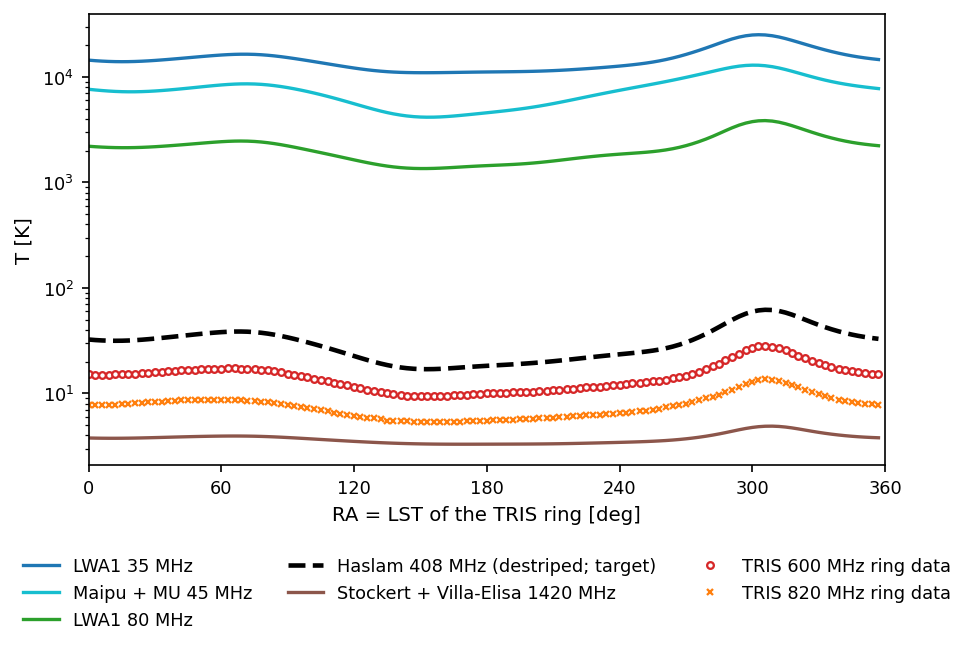

LWA1 35 MHz                        120/120 samples; TOD 10976.179–25154.724 K
Maipu + MU 45 MHz                  120/120 samples; TOD 4156.889–12943.606 K
LWA1 80 MHz                        120/120 samples; TOD 1355.365–3859.894 K
Haslam 408 MHz, destriped only     120/120 samples; TOD   16.985–  62.105 K
CHIPASS 1400 MHz                     0/120 samples (beam never ≥ half on observed sky): not drawn
Stockert + Villa-Elisa 1420 MHz    120/120 samples; TOD    3.303–   4.899 K
Rhodes/HartRAO 2326 MHz              0/120 samples (beam never ≥ half on observed sky): not drawn


In [7]:
fig, ax = plt.subplots(figsize=(FULL_WIDTH, 3.9))
order = [m for m in inp.fit_maps + [inp.target]]
order = sorted(order, key=lambda m: m["freq_mhz"])
for m in order:
    d = inp.tods[m["name"]]
    tod = np.where(d["good"], d["tod"], np.nan)
    if not np.isfinite(tod).any():
        continue
    is_target = m is inp.target
    colour = "k" if is_target else COLOUR[m["name"]]
    sparse = d["good"].sum() < 40           # ARCADE 2: only 16-17 samples; show them as points
    ax.plot(inp.ra, tod, color=colour, lw=2.2 if is_target else 1.6,
            ls="--" if is_target else "-", marker=("D" if "3.41" in m["name"] else "o") if sparse else None,
            ms=3.5, label=("Haslam 408 MHz (destriped; target)" if is_target else m["name"]))
for f, mk in ((600, "o"), (820, "x")):
    ring = inp.rings[f]
    ax.plot(ring.ra_deg, ring.temperature_k, mk, ms=3.2, mfc="white", mec=COLOUR[f"TRIS {f} MHz"], mew=1.1,
            label=f"TRIS {f} MHz ring data")
ax.set_yscale("log")
ax.set_xlim(0, 360); ax.set_xticks(np.arange(0, 361, 60))
ax.set_xlabel("RA = LST of the TRIS ring [deg]"); ax.set_ylabel("T [K]")
ax.legend(ncol=3, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.17))
save(fig, "tods_all_maps")
plt.show()
for m in order:
    d = inp.tods[m["name"]]
    n_good = int(d["good"].sum())
    if n_good:
        print(f"{m['name']:<34} {n_good:3d}/120 samples; TOD {np.nanmin(np.where(d['good'], d['tod'], np.nan)):8.3f}–"
              f"{np.nanmax(np.where(d['good'], d['tod'], np.nan)):8.3f} K")
    else:
        print(f"{m['name']:<34}   0/120 samples (beam never ≥ half on observed sky): not drawn")